# PokéChallenge 2026 — comparison with two other teams

After the challenge we rebuilt the models of two other teams and scored them on the same battles as ours. This document asks two questions:

1. How do the three teams compare when they are measured in the same way?
2. What can we say about the moves between the public and the private leaderboard?

| name here | team | public rank | private rank |
| --- | --- | --- | --- |
| ours | this repository: `compact_v5`, `v11`, `blend` | 2 | 1 |
| 2nd place | repository `FDS-Pokemon-Challenge-2026-2027` | 7 | 2 |
| 8th place | team Fantastic Four, repository `FDS-Challenge-2026` | 3 | 8 |

Each team sent three submissions. The tables list all nine. The figures show one per team: `blend` for us and, for the other two, the submission with their best private score.

What is measured and what is not:

- Sections 2 and 3 use only cross-validation on the 10,000 training battles, with every model rebuilt in this environment from its team's code.
- The public and private scores cannot be recomputed here, because the test labels are not available. They are the scores the teams report, and they are used only in section 4.

## 1. Setup

The notebook only reads the tables of `docs/evaluation/comparison/data/` and draws them (`draw.py`: pandas, numpy and matplotlib), so it runs in a few seconds and needs no competition data. The commands that produced the tables, which need the other teams' repositories and environments, are in the `README.md` next to this file.

- `REPOSITORY`: the project repository (pokechallenge-fall-2026)
- `REVISION = "main"`: the branch or tag that holds `docs/evaluation/comparison`

On Kaggle the repository is cloned (the notebook needs Internet access, in the notebook's settings) and the figures are saved in `/kaggle/working/figures`. In a local checkout the notebook uses the files next to it.

In [1]:
REPOSITORY = "https://github.com/CiottoloMaggico/pokechallenge-fall-2026.git"
REVISION = "main"  # the branch or tag that holds docs/evaluation/comparison

In [2]:
import os
import subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    CLONE = Path("/kaggle/temp/pokechallenge")  # not saved with the notebook
    if not CLONE.exists():
        command = ["git", "clone", "--quiet", "--depth", "1", "--branch", REVISION]
        skip_lfs = {**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}  # the battles are not needed
        subprocess.run([*command, REPOSITORY, str(CLONE)], check=True, env=skip_lfs)
    os.chdir(CLONE)
elif not Path("main.py").exists():  # this file is docs/evaluation/comparison/comparison.ipynb
    os.chdir(Path.cwd().resolve().parents[2])
# every path below is relative to the repository's root

In [3]:
import sys

import pandas as pd

sys.path.insert(0, str(Path("docs/evaluation/comparison").resolve()))
import draw

%matplotlib inline
draw.apple_style()
DATA = Path("docs/evaluation/comparison/data")
FIGURES = Path("/kaggle/working/figures" if ON_KAGGLE else "docs/evaluation/comparison/figures")


def table(name):
    return pd.read_csv(DATA / f"{name}.csv")


oof, metrics, board = table("oof"), table("metrics"), table("leaderboard")

## 2. How the comparison was made

- **Same battles, same folds.** The 10,000 training battles are split in the 5 folds of our own evaluation (seed 33, duplicated battles kept together). Each model is fitted on four folds and predicts the fifth, so every battle is predicted once by a model that has not seen it.
- **Their code, not ours.** The 2nd place models are trained by their own training script, and the 8th place notebooks are run cell by cell. We only replaced the fold assignment.
- **The 8th place notebooks are rerun once per fold**, with the four training folds as their training file and the fifth as their test file. Their own validation builds some lookup tables on all the training battles before splitting; rerunning the notebook avoids that. The difference turns out to be small (section 4.2).
- **Not rebuilt for the other teams:** the accuracy by last turn seen and the training loss, which are in our own evaluation. The figures below are the ones that could be drawn for all three teams.

Before comparing, we checked that the rebuilt models are the ones the teams describe:

| check | result |
| --- | --- |
| 2nd place, unit tests of their repository | 9 of 9 pass |
| 2nd place, accuracy with their own validation | 0.7106 and 0.7085, the values of their own rebuild on Kaggle |
| 2nd place, test predictions equal to the files they submitted | 4,964 and 4,922 of 5,000, the counts of their own rebuild on Kaggle |
| 8th place, accuracy and AUC of each fold of the three notebooks | equal to the values printed in their notebooks |

## 3. The three teams on the same folds

### 3.1 Performance

Accuracy and ROC AUC: higher is better. Log loss: lower is better. "± fold" is the standard deviation of the accuracy over the five folds.

In [4]:
draw.metrics_table(metrics, list(board["model"]))

Model,Accuracy,± fold,Log loss,ROC AUC
compact_v5,0.7184,0.0105,0.5407,0.7982
v11,0.7175,0.0047,0.5417,0.7979
blend,0.7232,0.0081,0.5355,0.8034
2nd: five views,0.7070,0.0129,0.5547,0.7860
2nd: five views + teams,0.7065,0.0122,0.5531,0.7867
2nd: tactical + teams,0.7084,0.0161,0.5546,0.7861
8th: boosters + CatBoost + LR,0.6941,0.0066,0.5698,0.7707
8th: CatBoost,0.6977,0.0075,0.5713,0.7691
8th: boosters + LR,0.6948,0.0047,0.5716,0.7688


The order is the same on the three metrics: our models first, then the 2nd place models, then the 8th place models. Taking one submission per team, `blend` reaches 72.3% accuracy, the 2nd place 70.8% and the 8th place 69.5%.

Inside each team the three submissions are close: at most 0.6 points of accuracy apart for us, 0.2 for the 2nd place and 0.4 for the 8th place. This is less than the fold-to-fold spread (0.5 to 1.6 points), so we do not rank the submissions of a team.

The spread across folds is also not small compared with the gaps between teams, so the table alone is not enough to say which gaps are real. The next table looks at that.

### 3.2 Differences fold by fold

For each pair of models we take the difference on each of the five folds. Two models are scored on the same battles, so part of the fold-to-fold variation cancels out in the difference. The p-value says how surprising the mean difference would be if the two models were equally good (the corrected test used everywhere in this repository, which takes into account that the folds share training battles). A small p means that the difference is larger than its variation across folds.

In [5]:
PAIRS = [
    ("blend", "second"),
    ("blend", "third"),
    ("second", "third"),
    ("compact_v5", "second"),
    ("v11", "second"),
    ("compact_v5", "third"),
    ("v11", "third"),
]
draw.paired_table(table("paired"), PAIRS)

Comparison,Δ accuracy (points),p,Δ log loss,p,Δ ROC AUC,p
blend − 2nd: tactical + teams,+1.48,0.130,-0.0191,0.003,+0.0174,0.005
blend − 8th: boosters + LR,+2.84,0.007,-0.0361,0.002,+0.0346,0.003
2nd: tactical + teams − 8th: boosters + LR,+1.36,0.182,-0.0170,0.036,+0.0173,0.048
compact_v5 − 2nd: tactical + teams,+1.00,0.079,-0.0139,0.012,+0.0121,0.013
v11 − 2nd: tactical + teams,+0.91,0.326,-0.0130,0.022,+0.0118,0.034
compact_v5 − 8th: boosters + LR,+2.36,0.009,-0.0309,0.006,+0.0294,0.007
v11 − 8th: boosters + LR,+2.27,0.002,-0.0300,0.005,+0.0291,0.005


- **`blend` and the 2nd place.** `blend` is 1.5 points higher in accuracy, but with p = 0.13 we cannot say that this gap is real. For log loss (−0.019, p = 0.003) and ROC AUC (+0.017, p = 0.005) the difference is clear: the probabilities of `blend` are better, even if the count of right answers does not separate the two with five folds.
- **`blend` and the 8th place.** The gap is 2.8 points of accuracy (p = 0.007) and it is clear on all three metrics.
- **Our single models.** `compact_v5` and `v11` are each about 1 point above the 2nd place in accuracy (p = 0.08 and 0.33, so not established) and better in log loss and ROC AUC (p between 0.01 and 0.03). Against the 8th place they are 2.3 points above, with p below 0.01.
- **2nd place and 8th place.** 1.4 points of accuracy (p = 0.18); the difference in log loss and ROC AUC is at the limit (p = 0.04 and 0.05).

Some caution is needed. There are five folds and one fold assignment, so the test is weak, and the table holds 21 comparisons, so a p around 0.03 is weaker evidence than it looks. Also, every team developed its models on these same 10,000 battles, so all the numbers are probably a little too good. We cannot measure by how much for each team.

### 3.3 ROC curves

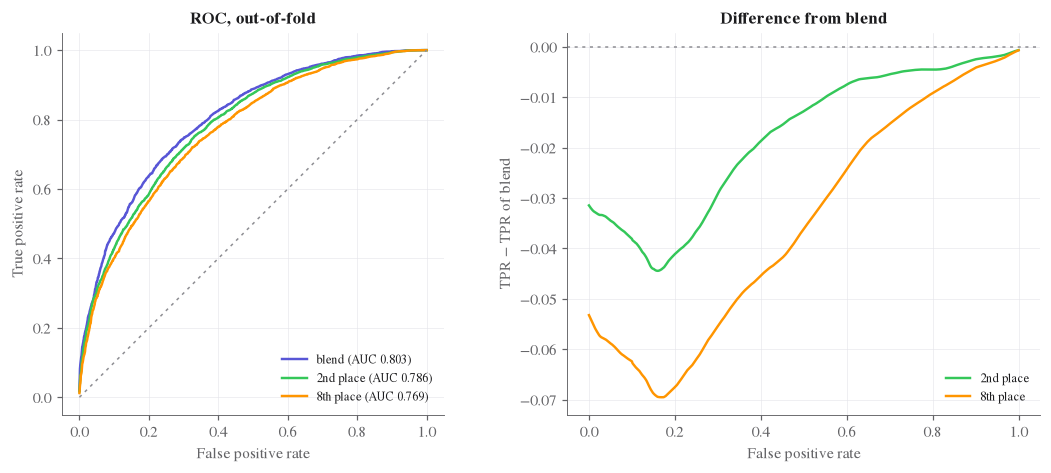

In [6]:
draw.plot_roc(oof, metrics, FIGURES);

The left panel shows one ROC curve per team, built from the 10,000 out-of-fold probabilities. The AUC values (0.803, 0.786, 0.769) are those of the table. The right panel plots the true positive rate of the other two teams minus that of `blend`, at each false positive rate.

Both lines are below zero everywhere: at every false positive rate `blend` finds at least as many of the real wins. The gap is largest at low false positive rates, about 4 points for the 2nd place and 7 for the 8th place around 0.15, and it closes towards the right. So the difference between the teams is larger for the battles on which the models are most sure than for the uncertain ones. These curves come from one run and have no confidence band.

### 3.4 Accuracy vs confidence

The confidence of a prediction is the probability the model gives to the winner it predicts, max(p, 1 − p). For each threshold t, the top panel shows the accuracy on the battles with confidence of at least t, and the bottom panel shows the share of battles that are left.

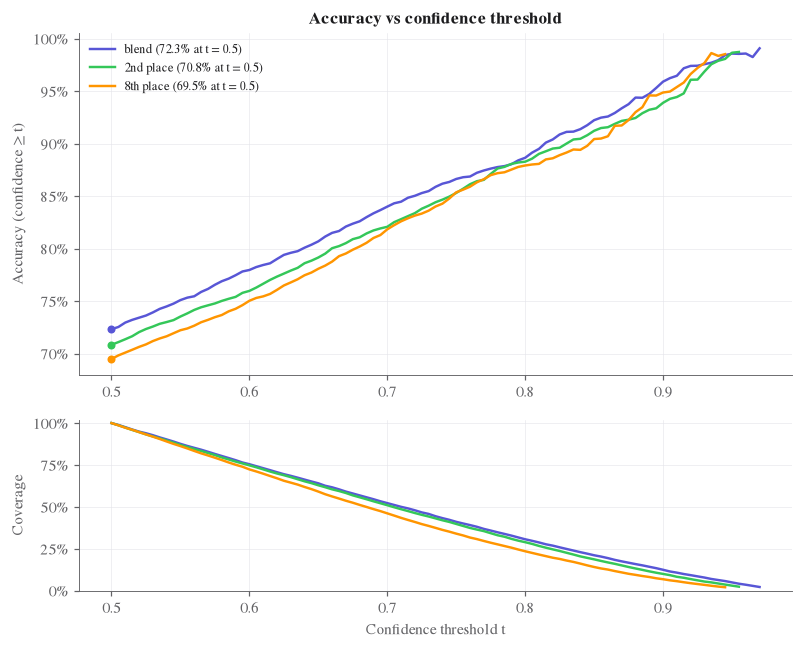

In [7]:
draw.plot_confidence(oof, DATA, FIGURES);

For all three teams accuracy grows steadily with confidence, so a high probability does mean a safer prediction.

| battles kept | `blend` | 2nd place | 8th place |
| --- | --- | --- | --- |
| confidence ≥ 0.7: share kept, accuracy | 52%, 84.0% | 51%, 82.1% | 46%, 81.8% |
| confidence ≥ 0.9: share kept, accuracy | 12%, 95.9% | 10%, 93.9% | 7%, 94.9% |

`blend` is above the other two up to a threshold of about 0.9 and keeps a few more battles at the same threshold. The 8th place model is confident less often (its coverage line is the lowest). Beyond 0.9 fewer than 1,300 battles remain and the lines are noisy.

### 3.5 Calibration

Calibration asks whether a probability can be taken at face value: among the battles to which a model gives about 70% for player 1, does player 1 win about 70% of them? A calibrated model lies on the diagonal. The bars show how many battles fall in each bin, and the ECE in the legend is the average distance from the diagonal.

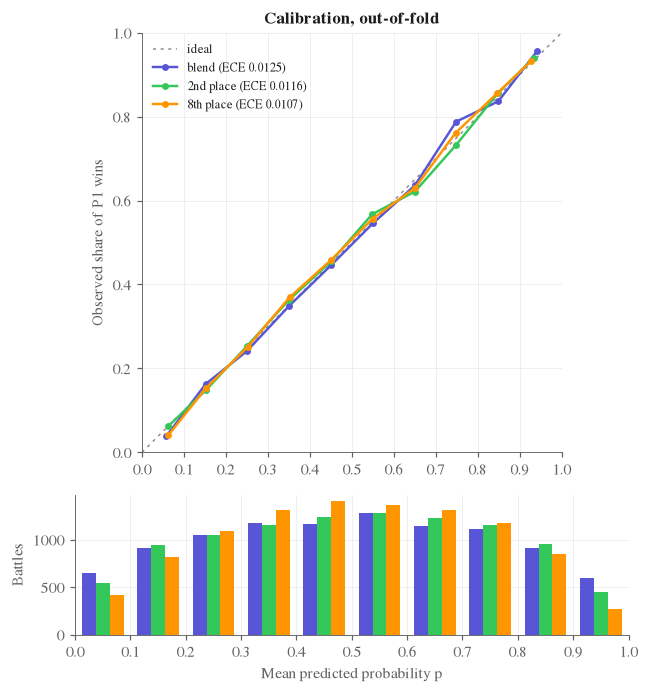

In [8]:
draw.plot_calibration(oof, DATA, FIGURES);

The three teams are all close to the diagonal (ECE 0.0125, 0.0116 and 0.0107), and the differences between them are of the size of the noise in a bin (about 1.3 points with 1,100 battles). The probabilities of the other teams can be trusted as much as ours.

So the better log loss of `blend` does not come from better calibration. It is more likely related to how well the models separate wins from losses (the ROC AUC), although we have not tested this directly. The bars agree: the 8th place model gives a probability below 0.1 or above 0.9 to 682 battles, the 2nd place to 998 and `blend` to 1,245.

### 3.6 Agreement between the teams

For each of the other two teams, we split the 10,000 battles into those on which its model and `blend` predict the same winner and those on which they predict different winners. Each bar is the accuracy of one model on one group, with an interval computed over battles.

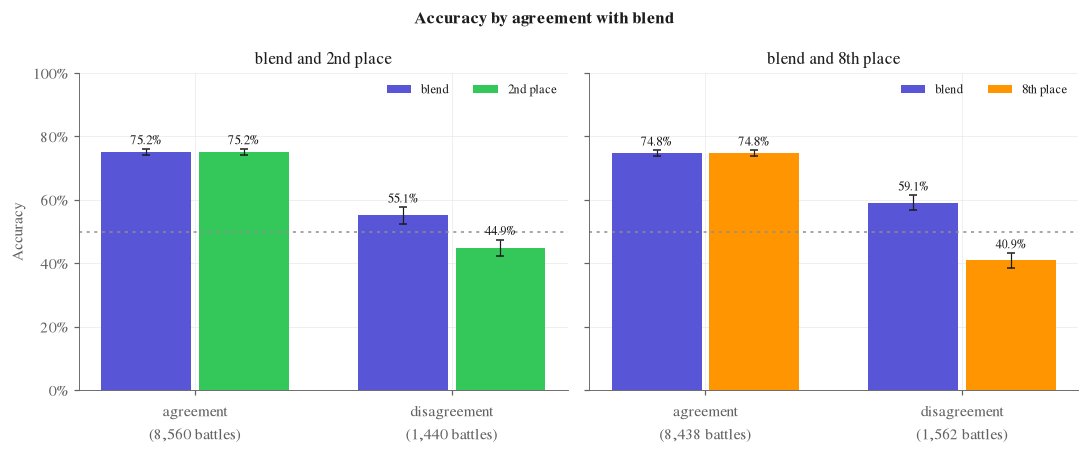

In [9]:
draw.plot_disagreement(draw.disagreement_table(oof, DATA), FIGURES);

`blend` and the 2nd place predict the same winner on 8,560 battles (85.6%), and both are right on 75.2% of them. They disagree on 1,440 battles (14.4%). There exactly one of the two is right, so the two bars add up to 100%: `blend` is right 55.1% of the time (interval 52.5% to 57.7%) and the 2nd place 44.9%.

With the 8th place the picture is the same and a little wider: agreement on 84.4% of the battles, and on the other 1,562 `blend` is right 59.1% of the time (56.7% to 61.5%).

For reference, `compact_v5` and `v11` agree on 88.3% of the battles. So the models of three teams, built independently, make the same call on about 85 battles out of 100. The whole gap in accuracy comes from the other 15, and on those `blend` is right more often than the other model, but far from always. On the test set the agreement is about the same (85.8% and 84.1%, `agreement.csv`).

### 3.7 Validation log loss by training size

For one validation fold (2,000 battles) each model is refitted from scratch on the first n of the other 8,000 battles, the same battles for the three teams. The 2nd place line is their main model without its last step (a small logistic regression that cannot be refitted in this experiment). `blend` has a point every 250 battles, the other two every 1,000.

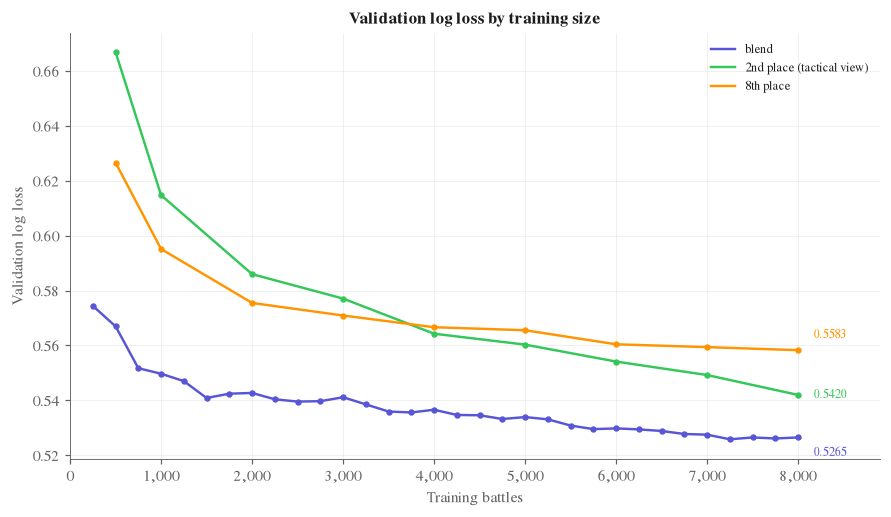

In [10]:
draw.plot_loss_convergence(table("loss_curve"), FIGURES);

`blend` is the lowest line at every size. With 500 battles it is at 0.567, against 0.627 for the 8th place and 0.667 for the 2nd place. With 8,000 the values are 0.527, 0.558 and 0.542.

The two other teams behave differently. The 2nd place model gains the most from data (from 0.667 to 0.542) and is still going down at 8,000 battles. The 8th place model is better than the 2nd place with little data but almost flat after 4,000 battles (0.567 to 0.558).

So in this experiment `blend` needs fewer battles to reach a given loss. The small number of features of `compact_v5` is a possible reason, but we have not tested it. The curves come from a single fold, so differences of a few thousandths are within noise.

## 4. Public and private leaderboard

The test file has 5,000 battles. The public leaderboard uses 1,500 of them (30%) and the private one the other 3,500 (70%). The scores below are the ones shown by Kaggle for our submissions and the ones the other teams report in their repositories (`data/leaderboard.csv`).

### 4.1 Cross-validation, public and private scores

Each row is a submission. The diamond is its accuracy in cross-validation on our folds (section 3.1), the empty circle its public score and the full circle its private score.

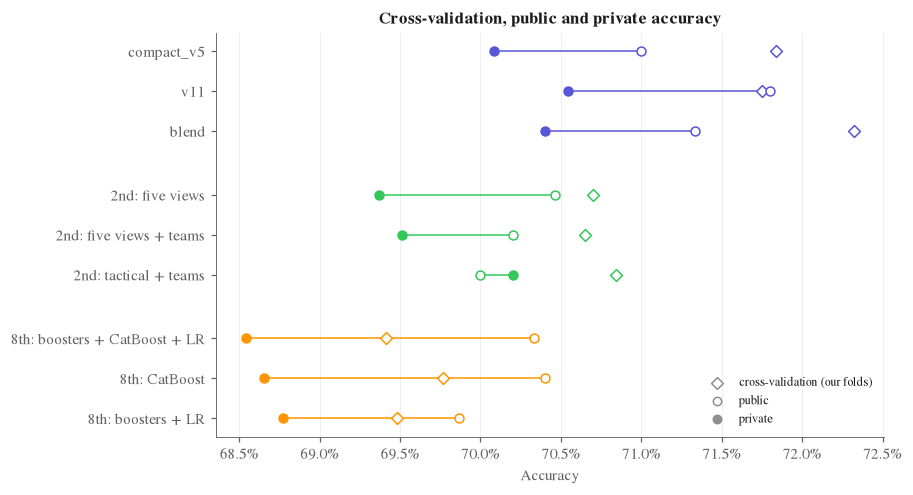

In [11]:
draw.plot_leaderboard(board, metrics, FIGURES);

In [12]:
draw.leaderboard_table(board, metrics)

Team,Submission,Cross-validation,Public,Private,Private − public (points)
ours,compact_v5,0.7184,0.7100,0.7008,-0.91
ours,v11,0.7175,0.7180,0.7054,-1.26
ours,blend,0.7232,0.7133,0.7040,-0.93
2nd place,2nd: five views,0.7070,0.7047,0.6937,-1.09
2nd place,2nd: five views + teams,0.7065,0.7020,0.6951,-0.69
2nd place,2nd: tactical + teams,0.7084,0.7000,0.7020,+0.20
8th place,8th: boosters + CatBoost + LR,0.6941,0.7033,0.6854,-1.79
8th place,8th: CatBoost,0.6977,0.7040,0.6866,-1.74
8th place,8th: boosters + LR,0.6948,0.6987,0.6877,-1.09


- **Every private score is below its cross-validation value**, by 0.6 to 1.9 points: 1.2 to 1.9 for ours, 0.6 to 1.3 for the 2nd place, 0.7 to 1.1 for the 8th place. The drop is not specific to one team, and ours is not the smallest. It could come from numbers that are a little too good because the models were chosen on the training battles, or from test battles that are slightly different. We cannot tell these apart.
- **The private order of the teams is the order of the cross-validation**: ours, 2nd place, 8th place.
- **On the public part our submissions are also first of the three** (71.0% to 71.8%), but the other two teams are not in that order: the 8th place submissions scored 69.9% to 70.4%, as high as the 2nd place (70.0% to 70.5%).
- **The public scores sit differently around the cross-validation values**: ours are equal or up to 1.0 point below, those of the 2nd place 0.2 to 0.8 below, those of the 8th place 0.4 to 0.9 above.
- Inside a team the two leaderboards do not agree on the best submission. For the 2nd place the best private score belongs to the lowest public score. For us `v11` is the best on both, while `blend`, the best in cross-validation, is between our two other submissions on both. These differences between submissions of one team are fractions of a point.

### 4.2 Was any team misled by its own validation?

A team could fall on the private leaderboard because its own validation was too optimistic. The table shows the accuracy of each team's models measured in three ways: with the team's own validation, on our folds validated as the team does, and on our folds with everything refitted on the training folds only (the values of section 3).

In [13]:
draw.estimates_table(table("estimates"))

Model,own validation,our folds,"our folds, refitted"
blend,0.7232,0.7232,0.7232
2nd: tactical + teams,0.7072,0.7084,0.7084
8th: boosters + LR,0.6984,0.6955,0.6948
8th: CatBoost,0.6968,0.6974,0.6977
8th: boosters + CatBoost + LR,0.7003,0.6939,0.6941


The three columns are close for every model. The 2nd place measured 70.7% and we find 70.8%. The 8th place measured 69.8% for their best private submission and we find 69.5% to 69.6%. Building their lookup tables on the training folds only changes almost nothing (69.55% against 69.48%). The largest gap, 0.6 points for one of their notebooks, is between two different fold assignments and is of the size of the fold noise.

So we find no sign that a team was misled by its validation. The 8th place cross-validation said about 69.8% and their private score is 68.8%, a drop like everyone else's. The number that stands out for them is the public one (up to 70.4%).

### 4.3 How much can a score move by chance?

We do not have the test labels, so we use the training battles as a stand-in. We draw 5,000 of them at random, call the first 1,500 "public" and the other 3,500 "private", and compute the accuracy of the out-of-fold predictions on each part. We repeat this 5,000 times. The histogram shows private minus public accuracy for `blend`. The triangles are the differences reported on the real leaderboard.

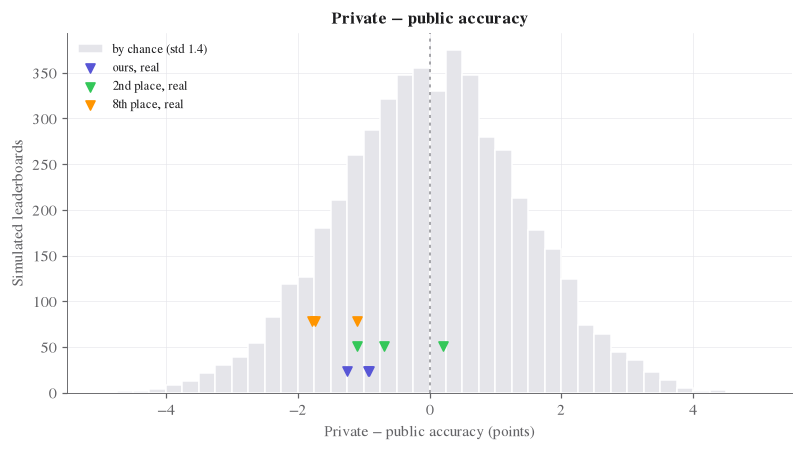

In [14]:
draw.plot_swing(table("split_simulation"), board, FIGURES);

By chance alone, the private score of a model differs from its public score with a standard deviation of 1.4 points. The value is the same for the three teams (1.4 for each). This is just the noise of measuring an accuracy near 70% on 1,500 and on 3,500 battles: a model does not need to change for its score to move by a point or two.

The real differences are inside this range: −0.9, −1.3 and −0.9 points for ours, +0.2, −0.7 and −1.1 for the 2nd place, −1.1, −1.7 and −1.8 for the 8th place. A move of at least 0.9 points in either direction happens in about half of the simulated leaderboards, and a drop of 1.7 points or more in about 11%. So each of these moves, taken alone, is compatible with chance.

Our own submissions lost about one point, like the others. The real scores give no sign that our models move less than theirs between the two parts.

Three things limit this reading:

- Eight of the nine differences are negative, but they are not nine independent facts. All the submissions are measured on the same split of the same test battles and mostly make the same predictions, so if the public battles happen to be a little easier, every score drops together. In the simulation the moves of two teams go together (correlation about 0.6), and the three teams move in the same direction in 58% of the simulated leaderboards.
- A team that is high on the public leaderboard is there partly because the public battles suited it, so on average such a team loses something on the private part. We cannot measure this without the scores of every team.
- The simulation uses training battles. It cannot explain why all the private scores are below the cross-validation values (section 4.1).

### 4.4 Gaps between teams

A rank depends on the gap between two teams, not on one score. Two teams are scored on the same battles and agree on most of them, so the gap moves less than a single score. The table shows, for each team's best private submission (for us `v11`), the gap in cross-validation and on the two leaderboards, in points of accuracy. "± chance" is the standard deviation of such a gap over the simulated leaderboards.

In [15]:
draw.gap_table(board, metrics, table("split_simulation"))

Gap,Cross-validation,Public,± chance,Private,± chance
v11 − 2nd: tactical + teams,+0.91,+1.80,0.9,+0.34,0.5
v11 − 8th: boosters + LR,+2.27,+1.93,0.9,+1.77,0.5
2nd: tactical + teams − 8th: boosters + LR,+1.36,+0.13,1.0,+1.43,0.5


- **By chance a gap moves by about 0.9 points on the public part and 0.5 on the private part.** On 1,500 battles, teams that are less than a point or two apart can easily swap places.
- **Ours and the 8th place.** The gap is 1.9 points on the public part and 1.8 on the private part, close to the 2.3 of the cross-validation. On the private part it is more than three times the chance value.
- **2nd place and 8th place.** The private gap (1.4 points) is the one of the cross-validation (1.4). On the public part it was 0.1 points, well inside the noise.
- **Ours and the 2nd place.** The gap is 1.8 points on the public part and 0.3 on the private part, on the two sides of the 0.9 of the cross-validation and each about one chance value away from it. The private gap is about 12 battles out of 3,500 and smaller than the chance value: the private leaderboard alone does not separate the first two places. The cross-validation is in our favour (section 3.2), clearly for log loss and ROC AUC and not clearly for accuracy.

One more caution about our own models: `compact_v5` scored 70.1% on the private part, just below the best 2nd place submission (70.2%), although it is 1.0 point above it in cross-validation. A change of this size is about twice the chance value. It agrees with the remark of our evaluation that the numbers of `compact_v5` are probably a little optimistic, because its features and hyper-parameters were selected on the training battles. One case is not enough to establish it.

## 5. Conclusions

- Measured on the same folds, the order of the teams is ours, 2nd place, 8th place, on accuracy, log loss and ROC AUC.
- Against the 8th place the gap is clear (2.8 points of accuracy for `blend`). Against the 2nd place `blend` has better probabilities (log loss and ROC AUC), while the 1.5 points of accuracy cannot be separated from noise with five folds.
- The three teams are equally well calibrated. The difference is in how well the models separate wins from losses, and it is largest on the confident predictions.
- The models of the three teams predict the same winner on about 85% of the battles. The gap comes from the other 15%, where `blend` is right 55% (against the 2nd place) and 59% (against the 8th place) of the time.
- In the one fold we tested, `blend` needs fewer training battles than the other two.
- The private leaderboard puts the three teams in the order of the cross-validation. On the public one we are also first of the three, but the 2nd and the 8th place are level.
- We find no sign that a team was misled by its own validation: each team's own estimate is close to ours.
- By chance alone a score moves by about 1.4 points between the public and the private part. The nine moves we know (from +0.2 to −1.8 points, ours about −1) are inside that range. So the data do not show that the fall of the 8th place or the rise of the 2nd place come from something in their models. They are compatible with a noisy public leaderboard of 1,500 battles.
- About our own stability: our scores dropped by about one point from the public to the private part, like the others', and the simulation gives no reason to think that our models move less. What the data support is simpler. Our gap over the 8th place is larger than the noise, so it holds on both parts. Our gap over the 2nd place on the private part (0.3 points) is not larger than the noise.

Limits: one fold assignment with five folds; cross-validation numbers that are probably a little optimistic for every team; leaderboard scores taken from Kaggle and from the teams' repositories, not reproduced; a simulation made on training battles, not on the test set.